# Experiment - Neighborhood context with an MLP

This experiment asks whether adding nearby tissue information improves spot-level gene prediction. It constructs neighborhood averages and fixed neighbor slots, uses patient folds, checks the ridge baseline, trains MLP variants, and plots fold-level comparisons.

Recorded patient-fold results: setup E (5x5 average) has pooled PCC 0.1997 and NRMSE 1.0702; mean-predictor NRMSE is 1.0997. The ridge reference reproduces PCC 0.1868 / NRMSE 1.0917. Saved output figures are retained in this copy. Validation metrics guide choices; held-out test scores are reported afterward.

This standalone notebook installs its own non-PyTorch dependencies. Install PyTorch separately using `README-new.md`, then set `DATA_DIR` in the settings cell to the prepared cohort folder. Cached outputs are historical results from the original run.


This notebook needs NumPy, pandas, SciPy, scikit-learn, and Matplotlib. PyTorch installation is hardware-specific; use the README instructions.

In [ ]:
%pip install -q numpy pandas scipy scikit-learn matplotlib
from pathlib import Path


# MLP_JK_Best — the current best MLP

**Current best:** setup **E** from **MLP_JK_03_window_comparison**.

This notebook always holds the MLP setup that currently predicts best. It is replaced only when a new experiment notebook beats it by the rule: highest **validation PCC** (validation patients are training patients, never the test fold), with validation NRMSE no worse than the mean predictor's. Test scores are reported, not used to choose.

The method: center spot → StandardScaler + PCA 256 (fit on training spots), plus the neighbor input of setup E; an MLP (hidden 128, dropout 0.3, weight decay 1e-3) with early stopping; shrinkage toward the training mean with `k` chosen on validation; 3 seeds averaged.

**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_Best/`. It doesn't add rows to `all_results.csv`, because it repeats an experiment that is already logged.

**Workflow overview:** imports the experiment?s data, plotting, and model libraries.

In [1]:
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores (ridge check and reference row).
- `REFERENCE_DIR`, `REFERENCE_SAVED_NAME`, `REFERENCE_NAME`, `REFERENCE_INPUT_SIZE`: the earlier MLP run shown as a reference row, and where its saved scores are.
- `CHECK_SETUP`: the setup that runs first and must land close to the reference row.
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5): `N_FOLDS`, `N_GENES`, `MIN_TEST_SD`, `SEED`, and the ridge settings `N_INNER_FOLDS`, `ALPHAS`.

**Inputs**
- `SETUPS`: which input setups to run (see the table above).
- `NEIGHBOR_DISTANCE`: how far a neighborhood reaches, in spot spacings. 1.8 = 3×3, 3.0 = 5×5 (as in Notebook 5).
- `SLOT_OFFSETS`: the fixed order of the 8 neighbor slots for B and C, as (dx, dy) steps on the spot grid. Slot 0 is always up-left, slot 1 always up, and so on.
- `N_PCS = 256`: PCA size for the center and for each average. `N_NEIGHBOR_PCS = 32`: how many numbers each neighbor keeps in setup C.

**MLP** (fixed at the MLP_JK_Best settings): `HIDDEN_SIZE`, `DROPOUT`, `WEIGHT_DECAY`, `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`, `SHRINK_FACTORS` (`k` values), `N_VAL_GROUPS` (validation groups of training patients), `N_FINAL_SEEDS`.

**Setup D check**: how far setup D may be from MLP_JK_Best before the notebook stops.

**Workflow overview:** sets the input data path and output folder.

In [2]:
DATA_DIR = Path("~/JHU/BDD/datasets/BDD_HEST").expanduser()  # set this to the prepared cohort folder
NOTEBOOK_5_DIR = Path("~/JHU/BDD/Experiments/smoothing_control").expanduser()
MLP_DIR = Path("~/JHU/BDD/MLP_JK").expanduser()
BEST_DIR = MLP_DIR / "results" / "MLP_JK_Best"
NOTEBOOK_NAME = "MLP_JK_Best"
LOG_RESULTS = False
SETUPS = ["E"]
REFERENCE_DIR = MLP_DIR / "results" / "MLP_JK_03"
REFERENCE_SAVED_NAME = "E 5x5 average"
REFERENCE_NAME = "MLP_JK_03 (logged)"
REFERENCE_INPUT_SIZE = 512
CHECK_SETUP = "E"
OUT_DIR = MLP_DIR / "results" / (NOTEBOOK_NAME)
RESULTS_LOG = MLP_DIR / "results" / "all_results.csv"

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = {"3x3": 1.8, "5x5": 3.0}
SLOT_OFFSETS = [(-1, -1), (0, -1), (1, -1), (-1, 0), (1, 0), (-1, 1), (0, 1), (1, 1)]
N_PCS = 256
N_NEIGHBOR_PCS = 32

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

SANITY_PCC_TOLERANCE = 0.02
SANITY_NRMSE_TOLERANCE = 0.015

The names and input sizes of the setups, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

**Workflow overview:** defines neighborhood/model variants and fixed seeds.

In [3]:
SETUP_NAMES = {
    "A": "A center only",
    "B": "B 3x3 separate",
    "C": "C 3x3 separate, compressed",
    "D": "D 3x3 average",
    "E": "E 5x5 average",
}
INPUT_SIZES = {
    "A": N_PCS,
    "B": N_PCS + 8 * N_PCS,
    "C": N_PCS + 8 * N_NEIGHBOR_PCS,
    "D": 2 * N_PCS,
    "E": 2 * N_PCS,
}

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = DATA_DIR / "expression"
EMBEDDING_DIR = DATA_DIR / "embeddings"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.savefig(OUT_DIR / (name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

**Workflow overview:** loads and checks embeddings, expression, and spot identities.

In [4]:
spot_table = pd.read_csv(DATA_DIR / "spot_table.csv")
with Path(DATA_DIR / "genes.txt").open() as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(EMBEDDING_DIR / f"{sample_id}.npz", allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(EXPRESSION_DIR / f"{sample_id}.npz")
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods (same definition as Notebook 5) and neighbor slots

**Neighborhoods for the averages (D, E)**, copied from Notebook 5. For each section, the spot spacing = median distance from a spot to its closest other spot. A spot's neighborhood = every spot on the same section within 1.8 spacings (3×3) or 3.0 spacings (5×5), **including the spot itself**. Edge spots are averaged over whatever neighbors exist.

**Workflow overview:** computes spatial neighborhoods and their average features.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10 | full (9): 70.7%
5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


**Neighbor slots for B and C.** Here each neighbor keeps its position. For every spot, each 3×3 neighbor's offset from the center is divided by the spot spacing and rounded to whole grid steps, (dx, dy). That step decides its slot, in the fixed order of `SLOT_OFFSETS`, so slot 1 always holds the spot directly above (in image coordinates), slot 4 the spot to the right, and so on.

- If two spots round to the same slot (rare, from small irregularities in the grid), the one closer to the exact grid position is kept.
- If a slot is empty (tissue edge or a missing spot), it gets the **center spot's own embedding**.

`neighbor_slots` is a table of row numbers, one row per spot and one column per slot. It says which spot's embedding goes into which slot.

**Workflow overview:** maps nearby spots into fixed relative-position slots.

In [6]:
def find_neighbor_slots(max_distance):
    n_spots = len(spots)
    neighbor_slots = np.tile(np.arange(n_spots)[:, None], (1, len(SLOT_OFFSETS)))
    slot_found = np.zeros((n_spots, len(SLOT_OFFSETS)), dtype=bool)
    total_nearby = 0

    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)

        for i, nearby in enumerate(nearby_lists):
            best_error = np.full(len(SLOT_OFFSETS), np.inf)
            for j in nearby:
                if j == i:
                    continue
                total_nearby += 1
                offset = (xy[j] - xy[i]) / spacing
                grid_step = (int(round(offset[0])), int(round(offset[1])))
                if grid_step not in SLOT_OFFSETS:
                    continue
                slot = SLOT_OFFSETS.index(grid_step)
                error = np.sum((offset - np.array(grid_step)) ** 2)
                if error < best_error[slot]:
                    best_error[slot] = error
                    neighbor_slots[rows[i], slot] = rows[j]
                    slot_found[rows[i], slot] = True

    return neighbor_slots, slot_found, total_nearby


neighbor_slots, slot_found, total_nearby = find_neighbor_slots(NEIGHBOR_DISTANCE["3x3"])
missing_per_spot = (~slot_found).sum(axis=1)

print(f"Neighbors within 1.8 spacings: {total_nearby}")
print(f"  placed in a slot: {slot_found.sum()}   not placed (outside the 3x3 steps, or a second spot in a slot): "
      f"{total_nearby - slot_found.sum()}")
print(f"Spots with at least one missing neighbor: {np.sum(missing_per_spot > 0)} of {len(spots)} "
      f"({np.mean(missing_per_spot > 0):.1%})")
print("Missing slots per spot (count of spots):")
print(pd.Series(missing_per_spot).value_counts().sort_index().to_string())
print("Share of spots with each slot filled:")
for slot, step in enumerate(SLOT_OFFSETS):
    print(f"  slot {slot} (dx, dy) = {step}: {slot_found[:, slot].mean():.1%}")

Neighbors within 1.8 spacings: 223488
  placed in a slot: 223480   not placed (outside the 3x3 steps, or a second spot in a slot): 8
Spots with at least one missing neighbor: 8956 of 30600 (29.3%)
Missing slots per spot (count of spots):
0    21644
1     3284
2     1369
3     2533
4     1292
5      371
6       77
7       26
8        4
Share of spots with each slot filled:
  slot 0 (dx, dy) = (-1, -1): 90.0%
  slot 1 (dx, dy) = (0, -1): 92.4%
  slot 2 (dx, dy) = (1, -1): 89.7%
  slot 3 (dx, dy) = (-1, 0): 93.0%
  slot 4 (dx, dy) = (1, 0): 93.0%
  slot 5 (dx, dy) = (-1, 1): 89.7%
  slot 6 (dx, dy) = (0, 1): 92.4%
  slot 7 (dx, dy) = (1, 1): 90.0%


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

**Workflow overview:** assigns patient-level folds.

In [7]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

**Workflow overview:** selects training genes and defines evaluation metrics.

In [8]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

**Workflow overview:** reproduces ridge and verifies the historical baseline.

In [9]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


**Workflow overview:** performs the next calculation in the experiment.

In [10]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(NOTEBOOK_5_DIR / "summary.csv").set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. PCA inputs for every fold

In each fold, on the **training spots only**, three StandardScaler + PCA 256 transformations are fit:
- `center`: the spots' own embeddings. This is the same transformation ridge uses.
- `mean_3x3`: the 3×3 averaged embeddings (for D).
- `mean_5x5`: the 5×5 averaged embeddings (for E).

Each is then applied to every spot. The neighbors in B and C use the **center PCA**: it is the one shared PCA fit on the training spots' own embeddings, so a neighbor is described in exactly the same way as a center spot. For C, each neighbor keeps only its first 32 components. PCA components are sorted by how much variation they explain, so the first 32 are the same as a PCA with 32 components.

The PCA results are small (30,600 × 256 per input per fold), so all of them are kept. The large 4,608-wide arrays are deleted afterwards to free memory.

**Workflow overview:** fits PCA representations using training spots only.

In [11]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_3x3 = neighbor_mean(X_raw, neighborhoods["3x3"])
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
print(f"Averages done ({(time.time() - start_time) / 60:.1f} min)")

fold_inputs = []
for fold in range(N_FOLDS):
    train_index = np.where(fold_of_spot != fold)[0]
    fold_inputs.append({
        "center": pca_256(X_raw, train_index),
        "mean_3x3": pca_256(X_mean_3x3, train_index),
        "mean_5x5": pca_256(X_mean_5x5, train_index),
    })
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

del X_raw, X_mean_3x3, X_mean_5x5

Averages done (0.0 min)


fold 0: PCA inputs done (0.2 min)


fold 1: PCA inputs done (0.5 min)


fold 2: PCA inputs done (0.7 min)


fold 3: PCA inputs done (0.9 min)


**`build_input`** puts together the input of one setup in one fold, by placing blocks side by side. For B and C, `center[neighbor_slots[:, slot]]` looks up the PCA numbers of the spot in that slot for every spot (or the center itself when the slot is empty).

**Workflow overview:** assembles center and neighbor inputs.

In [12]:
def build_input(setup, fold):
    center = fold_inputs[fold]["center"]
    if setup == "A":
        return center
    if setup == "B":
        parts = [center]
        for slot in range(len(SLOT_OFFSETS)):
            parts.append(center[neighbor_slots[:, slot]])
        return np.concatenate(parts, axis=1)
    if setup == "C":
        parts = [center]
        for slot in range(len(SLOT_OFFSETS)):
            parts.append(center[neighbor_slots[:, slot], :N_NEIGHBOR_PCS])
        return np.concatenate(parts, axis=1)
    if setup == "D":
        return np.concatenate([center, fold_inputs[fold]["mean_3x3"]], axis=1)
    if setup == "E":
        return np.concatenate([center, fold_inputs[fold]["mean_5x5"]], axis=1)
    raise ValueError(f"unknown setup {setup}")


for setup in SETUPS:
    shape = build_input(setup, 0).shape
    assert shape[1] == INPUT_SIZES[setup]
    print(f"{SETUP_NAMES[setup]:28s}: {shape[0]} spots x {shape[1]} numbers")

E 5x5 average               : 30600 spots x 512 numbers


## Step 7. The MLP, training, and shrinkage (as in MLP_JK_02, with the settings fixed)

**The network**: input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50 genes), with no activation at the end (regression).

**`train_mlp`**: Adam (weight decay 1e-3), MSE loss on genes standardized with the training mean and SD, mini-batches of 256. With validation spots, the weights from the best validation epoch are kept, and training stops after `PATIENCE` epochs without improvement. Without validation spots, it trains for a fixed number of epochs.

**`predict`**: dropout off, predictions converted back to log1p units.

**`shrink`**: `train_mean + k × (prediction − train_mean)`. Shrinking doesn't change PCC; it only changes how spread out the predictions are, so `k` is chosen on NRMSE.

**Workflow overview:** defines the MLP architecture.

In [13]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 8. One setup in one fold, start to finish

Everything that learns from data uses the fold's **training patients only**:

| Step | Uses |
|---|---|
| Top-50 genes | training spots (chosen once per fold, the same genes for every setup and for ridge) |
| PCA inputs | training spots (Step 6) |
| Choose `k` and the number of epochs | 4 validation groups of training patients. Each group takes a turn as validation while the MLP trains on the other 3. `k` = lowest validation NRMSE averaged over the 4 groups; epochs = median best epoch |
| Final models | **all** training patients, 3 seeds (0, 1, 2), each trained for that many epochs |
| Test patients | used once: the 3 seeds' predictions are averaged and shrunk with `k` toward the training mean |

Each seed's own (shrunk) test predictions are also kept, to measure how much the scores move from seed to seed. As before, the test spots' expression is `NaN` in the array the training reads.

**Workflow overview:** runs the fold-level training and evaluation.

In [14]:
fold_genes = []
for fold in range(N_FOLDS):
    fold_genes.append(choose_genes(np.where(fold_of_spot != fold)[0]))


def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_setup_fold(setup, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    P_device = to_device(build_input(setup, fold))

    val_rows = []
    histories = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {
            "fold": fold,
            "test_index": val_index,
            "genes": genes,
            "y_test": y_fold[val_index],
            "y_mean": np.tile(fit_mean, (len(val_index), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_pred = predict(trained, P_device, val_index)
        for k in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, k)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({
                "setup": setup, "fold": fold, "val_group": group, "k": k,
                "val_PCC": scores["PCC"].mean(),
                "val_NRMSE": scores["NRMSE"].mean(),
                "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                "best_epoch": trained["best_epoch"],
            })
        history = pd.DataFrame(trained["history"])
        history["setup"] = setup
        history["fold"] = fold
        history["val_group"] = group
        histories.append(history)

    val_table = pd.DataFrame(val_rows)
    by_k = val_table.groupby("k").agg(
        val_PCC=("val_PCC", "mean"),
        val_NRMSE=("val_NRMSE", "mean"),
        val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
        epochs=("best_epoch", "median"),
    ).reset_index()
    chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
    chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
    n_epochs = max(1, int(round(chosen["epochs"])))

    train_mean = y_fold[train_index].mean(axis=0)
    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, n_epochs, SEED + seed_number)
        seed_predictions.append(predict(final, P_device, test_index))
    del P_device

    y_test = Y[test_index][:, gene_index].toarray()
    test_result = {
        "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
        "y_pred": shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]),
        "alpha": no_alpha,
    }
    seed_results = []
    for prediction in seed_predictions:
        seed_results.append({
            "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
            "y_pred": shrink(prediction, train_mean, chosen["k"]),
            "alpha": no_alpha,
        })

    chosen.update({"setup": setup, "fold": fold, "final_epochs": n_epochs, "input_size": INPUT_SIZES[setup]})
    return test_result, seed_results, val_table, pd.concat(histories, ignore_index=True), chosen


mlp_results = {}
seed_results = {}
val_tables = []
history_tables = []
chosen_rows = []


def run_setup(setup):
    mlp_results[setup] = []
    seed_results[setup] = [[] for _ in range(N_FINAL_SEEDS)]
    for fold in range(N_FOLDS):
        test_result, fold_seed_results, val_table, history, chosen = run_setup_fold(setup, fold)
        mlp_results[setup].append(test_result)
        for seed_number in range(N_FINAL_SEEDS):
            seed_results[setup][seed_number].append(fold_seed_results[seed_number])
        val_tables.append(val_table)
        history_tables.append(history)
        chosen_rows.append(chosen)
        print(f"{SETUP_NAMES[setup]:28s} fold {fold}: k = {chosen['k']}, {chosen['final_epochs']} epochs  "
              f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

## Step 9. Test MSE, and the reference rows

**Test MSE** is the loss Task 4 asks for: the average squared difference between predicted and true log1p expression. It's computed per gene over all test spots of a fold, then averaged over genes and folds. It is the square of the error that NRMSE divides by the gene's SD, so `MSE = (NRMSE × test SD)²` for each gene. That formula also gives the MSE of the reference rows from their saved NRMSE, so every row is computed the same way.

**Reference rows**: the mean predictor and ridge raw (run here), the best ridge (`center+mean-3x3`, read from Notebook 5), and the reference MLP set in Settings (`REFERENCE_NAME`, read from its saved scores). The check makes sure the saved rows use the same genes in every fold.

**Workflow overview:** collects reference and validation statistics.

In [15]:
test_sd_rows = []
for fold in range(N_FOLDS):
    test_index = np.where(fold_of_spot == fold)[0]
    y_test = Y[test_index][:, fold_genes[fold]].toarray()
    for g, gene in enumerate(all_genes[fold_genes[fold]]):
        test_sd_rows.append({"fold": fold, "gene": gene, "test_SD": np.std(y_test[:, g])})
test_sd = pd.DataFrame(test_sd_rows)


def add_mse(pooled_table):
    table = pooled_table.drop(columns=["test_SD", "MSE"], errors="ignore")
    table = table.merge(test_sd, on=["fold", "gene"], how="left")
    table["MSE"] = (table["NRMSE"] * table["test_SD"]) ** 2
    return table


def read_saved_scores(folder, saved_name, new_name):
    pooled = pd.read_csv(folder / "pooled_gene_scores.csv")
    within = pd.read_csv(folder / "within_patient_gene_scores.csv")
    pooled = pooled[pooled["model"] == saved_name].copy()
    within = within[within["model"] == saved_name].copy()
    pooled["model"] = new_name
    within["model"] = new_name
    for fold in range(N_FOLDS):
        saved_genes = set(pooled.loc[pooled["fold"] == fold, "gene"])
        assert saved_genes == set(all_genes[fold_genes[fold]]), f"{new_name}, fold {fold}: genes differ"
    return pooled, within


ridge_reference_name = "ridge center+mean-3x3 (Notebook 5)"
ridge_reference_pooled, ridge_reference_within = read_saved_scores(
    NOTEBOOK_5_DIR, "ridge center+mean-3x3", ridge_reference_name)
reference_mlp_pooled, reference_mlp_within = read_saved_scores(REFERENCE_DIR, REFERENCE_SAVED_NAME, REFERENCE_NAME)
reference_pcc = reference_mlp_pooled["PCC"].mean()
reference_nrmse = reference_mlp_pooled["NRMSE"].mean()

reference_summary = pd.read_csv(REFERENCE_DIR / "summary.csv").set_index("model").loc[REFERENCE_SAVED_NAME]
reference_val_PCC = reference_summary["val_PCC"]
reference_val_NRMSE = reference_summary["val_NRMSE"]
reference_chosen = pd.read_csv(REFERENCE_DIR / "chosen_settings.csv")
if "setup" in reference_chosen.columns:
    reference_chosen = reference_chosen[reference_chosen["setup"] == CHECK_SETUP]
reference_chosen = reference_chosen.sort_values("fold")
print("Reference rows match our genes in every fold.")
print(f"{REFERENCE_NAME}: test pooled PCC {reference_pcc:.4f}, NRMSE {reference_nrmse:.4f}, "
      f"validation PCC {reference_val_PCC:.4f}")


def score_setup(setup):
    pooled, within = score_model(SETUP_NAMES[setup], mlp_results[setup], "y_pred")
    return add_mse(pooled), within

Reference rows match our genes in every fold.
MLP_JK_03 (logged): test pooled PCC 0.1997, NRMSE 1.0702, validation PCC 0.2256


## Step 10. Run setup E, and check it against the logged MLP_JK_03 run

This notebook repeats setup E from MLP_JK_03, so the numbers should be nearly identical (the Apple GPU can differ in the third decimal). If pooled PCC is more than 0.02 away, or NRMSE more than 0.015 away, the notebook stops.

**Workflow overview:** checks setup E against the prior logged run.

In [16]:
start_time = time.time()
run_setup(CHECK_SETUP)
check_pooled, _ = score_setup(CHECK_SETUP)
check_pcc = check_pooled["PCC"].mean()
check_nrmse = check_pooled["NRMSE"].mean()
print(f"\nSetup {CHECK_SETUP}: pooled PCC {check_pcc:.4f}, NRMSE {check_nrmse:.4f}")
print(f"{REFERENCE_NAME}: pooled PCC {reference_pcc:.4f}, NRMSE {reference_nrmse:.4f}")
assert abs(check_pcc - reference_pcc) <= SANITY_PCC_TOLERANCE, \
    f"Setup {CHECK_SETUP}'s PCC is far from {REFERENCE_NAME}. Stop and check before going further."
assert abs(check_nrmse - reference_nrmse) <= SANITY_NRMSE_TOLERANCE, \
    f"Setup {CHECK_SETUP}'s NRMSE is far from {REFERENCE_NAME}. Stop and check before going further."
print(f"Setup {CHECK_SETUP} is close to {REFERENCE_NAME}.")

E 5x5 average                fold 0: k = 0.4, 8 epochs  (0.1 min)


E 5x5 average                fold 1: k = 0.4, 10 epochs  (0.3 min)


E 5x5 average                fold 2: k = 0.4, 12 epochs  (0.5 min)


E 5x5 average                fold 3: k = 0.4, 12 epochs  (0.6 min)



Setup E: pooled PCC 0.1997, NRMSE 1.0702
MLP_JK_03 (logged): pooled PCC 0.1997, NRMSE 1.0702
Setup E is close to MLP_JK_03 (logged).


## Step 11. Run the other setups

**Workflow overview:** runs additional neighborhood configurations.

In [17]:
for setup in SETUPS:
    if setup != CHECK_SETUP:
        run_setup(setup)

val_scores = pd.concat(val_tables, ignore_index=True)
loss_history = pd.concat(history_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows).sort_values(["setup", "fold"]).reset_index(drop=True)
print("All setups done.")

All setups done.


## Step 12. Results

**Chosen `k` and epochs per fold.** These are chosen on validation patients, separately for each setup and fold. `val_PCC` and `val_NRMSE` are averaged over the 4 validation groups; `passes` means validation NRMSE is no worse than the mean predictor's.

**Workflow overview:** prepares aggregate tables.

In [18]:
pd.set_option("display.width", 250)
columns = ["setup", "fold", "input_size", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings[columns].round(4).to_string(index=False))

setup  fold  input_size   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
    E     0         512 0.4             8   0.2803     1.0994                    1.1430    True
    E     1         512 0.4            10   0.1757     1.1128                    1.1307    True
    E     2         512 0.4            12   0.2052     1.0659                    1.0955    True
    E     3         512 0.4            12   0.2412     1.0577                    1.0824    True


**Results table** (test patients, 4 folds). Test MSE and NRMSE: lower is better. Pooled and within-patient PCC: higher is better. The validation columns are what any choice is based on. `chosen_k` lists the `k` of folds 0–3.

**Workflow overview:** compares mean, ridge, and MLP models.

In [19]:
pooled_tables = [add_mse(mean_pooled), add_mse(ridge_pooled), add_mse(ridge_reference_pooled), add_mse(reference_mlp_pooled)]
within_tables = [mean_within, ridge_within, ridge_reference_within, reference_mlp_within]
for setup in SETUPS:
    p, w = score_setup(setup)
    pooled_tables.append(p)
    within_tables.append(w)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)

reference_order = ["mean predictor", "ridge raw", ridge_reference_name, REFERENCE_NAME]
setup_order = [SETUP_NAMES[s] for s in SETUPS]
model_order = reference_order + setup_order

summary_rows = []
for model_name in model_order:
    p = pooled[pooled["model"] == model_name]
    w = within[within["model"] == model_name]
    row = {
        "model": model_name,
        "input_size": np.nan,
        "test_MSE": p["MSE"].mean(),
        "pooled_PCC": p["PCC"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "NRMSE": p["NRMSE"].mean(),
        "val_PCC": np.nan,
        "val_NRMSE": np.nan,
        "chosen_k": "",
    }
    if model_name == "ridge raw":
        row["input_size"] = N_PCS
    if model_name == REFERENCE_NAME:
        row["input_size"] = REFERENCE_INPUT_SIZE
        row["val_PCC"] = reference_val_PCC
        row["val_NRMSE"] = reference_val_NRMSE
        row["chosen_k"] = "/".join(str(k) for k in reference_chosen["k"])
    if model_name in setup_order:
        setup = SETUPS[setup_order.index(model_name)]
        c = chosen_settings[chosen_settings["setup"] == setup]
        row["input_size"] = INPUT_SIZES[setup]
        row["val_PCC"] = c["val_PCC"].mean()
        row["val_NRMSE"] = c["val_NRMSE"].mean()
        row["chosen_k"] = "/".join(str(k) for k in c["k"])
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
print(summary.round(4).to_string(index=False))
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

                             model  input_size  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k
                    mean predictor         NaN    1.0092         NaN         NaN 1.0997      NaN        NaN                
                         ridge raw       256.0    0.9837      0.1868      0.1514 1.0917      NaN        NaN                
ridge center+mean-3x3 (Notebook 5)         NaN    0.9890      0.2034      0.1605 1.0930      NaN        NaN                
                MLP_JK_03 (logged)       512.0    0.9589      0.1997      0.1694 1.0702   0.2256      1.084 0.4/0.4/0.4/0.4
                     E 5x5 average       512.0    0.9589      0.1997      0.1694 1.0702   0.2256      1.084 0.4/0.4/0.4/0.4


**Seed spread.** Each of the 3 final models (seeds 0, 1, 2) is scored on its own, with the same `k` and averaged over the 4 folds. The table shows the lowest and highest of the 3. If two setups differ by less than this spread, the difference could just be the luck of the random start. The averaged ensemble (the main result) is often a bit better than any single seed.

**Workflow overview:** summarizes variation across random seeds.

In [20]:
spread_rows = []
for setup in SETUPS:
    seed_pcc = []
    seed_mse = []
    seed_nrmse = []
    for seed_number in range(N_FINAL_SEEDS):
        p, _ = score_model("seed", seed_results[setup][seed_number], "y_pred")
        p = add_mse(p)
        seed_pcc.append(p["PCC"].mean())
        seed_mse.append(p["MSE"].mean())
        seed_nrmse.append(p["NRMSE"].mean())
    spread_rows.append({
        "model": SETUP_NAMES[setup],
        "PCC_min": min(seed_pcc), "PCC_max": max(seed_pcc), "PCC_range": max(seed_pcc) - min(seed_pcc),
        "MSE_min": min(seed_mse), "MSE_max": max(seed_mse), "MSE_range": max(seed_mse) - min(seed_mse),
        "NRMSE_min": min(seed_nrmse), "NRMSE_max": max(seed_nrmse),
    })
seed_spread = pd.DataFrame(spread_rows)
print(seed_spread.round(4).to_string(index=False))

        model  PCC_min  PCC_max  PCC_range  MSE_min  MSE_max  MSE_range  NRMSE_min  NRMSE_max
E 5x5 average   0.1926   0.1963     0.0037   0.9599   0.9613     0.0014     1.0704      1.072


**Per-fold tables.** Each fold has different test patients. A setup that is better in most folds is more convincing than one that is better only on average.

**Workflow overview:** shows held-out performance by fold.

In [21]:
fold_scores = pooled.groupby(["model", "fold"]).agg(
    MSE=("MSE", "mean"), PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
within_fold = within.groupby(["model", "fold"])["PCC_within"].mean().reset_index()
fold_scores = fold_scores.merge(within_fold, on=["model", "fold"])

for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC"), ("NRMSE", "Pooled NRMSE"), ("PCC_within", "Within-patient PCC")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(model_order).round(4).to_string())
    print()

Test MSE per fold:
fold                                     0       1       2       3
model                                                             
mean predictor                      1.0422  1.1320  0.9242  0.9386
ridge raw                           1.0687  1.0381  0.9487  0.8792
ridge center+mean-3x3 (Notebook 5)  1.1148  1.0121  0.9571  0.8720
MLP_JK_03 (logged)                  1.0082  1.0451  0.8869  0.8952
E 5x5 average                       1.0082  1.0451  0.8869  0.8952

Pooled PCC per fold:
fold                                     0       1       2       3
model                                                             
mean predictor                         NaN     NaN     NaN     NaN
ridge raw                           0.1576  0.3129  0.0903  0.1864
ridge center+mean-3x3 (Notebook 5)  0.1661  0.3437  0.1112  0.1925
MLP_JK_03 (logged)                  0.2359  0.2966  0.1269  0.1393
E 5x5 average                       0.2359  0.2966  0.1269  0.1393

Pooled NRMSE per fol

**The four Task 4 comparisons, fold by fold.** Each line is the difference in pooled PCC and in test MSE between two setups, per fold. For MSE, negative means the first setup has the lower (better) loss.

**Workflow overview:** computes paired per-fold differences.

In [22]:
comparisons = [("D", "A"), ("B", "A"), ("E", "A"), ("C", "B"), ("C", "D"), ("E", "D")]
pcc_table = fold_scores.pivot(index="model", columns="fold", values="PCC")
mse_table = fold_scores.pivot(index="model", columns="fold", values="MSE")
for first, second in comparisons:
    if first not in SETUPS or second not in SETUPS:
        continue
    a = SETUP_NAMES[first]
    b = SETUP_NAMES[second]
    pcc_difference = pcc_table.loc[a] - pcc_table.loc[b]
    mse_difference = mse_table.loc[a] - mse_table.loc[b]
    print(f"{first} - {second}:  PCC " + " ".join(f"{d:+.3f}" for d in pcc_difference)
          + f"  (mean {pcc_difference.mean():+.4f}, {first} higher in {(pcc_difference > 0).sum()}/4)"
          + "   |  MSE " + " ".join(f"{d:+.4f}" for d in mse_difference)
          + f"  (mean {mse_difference.mean():+.4f}, {first} lower in {(mse_difference < 0).sum()}/4)")

## Step 13. Plots

**Test MSE and pooled PCC per setup.** Bars are the average over folds; dots are the 4 folds. For the setups, the black line shows the range across the 3 seeds (lowest to highest). The dashed line is the mean predictor's MSE.

**Workflow overview:** sets figure colors.

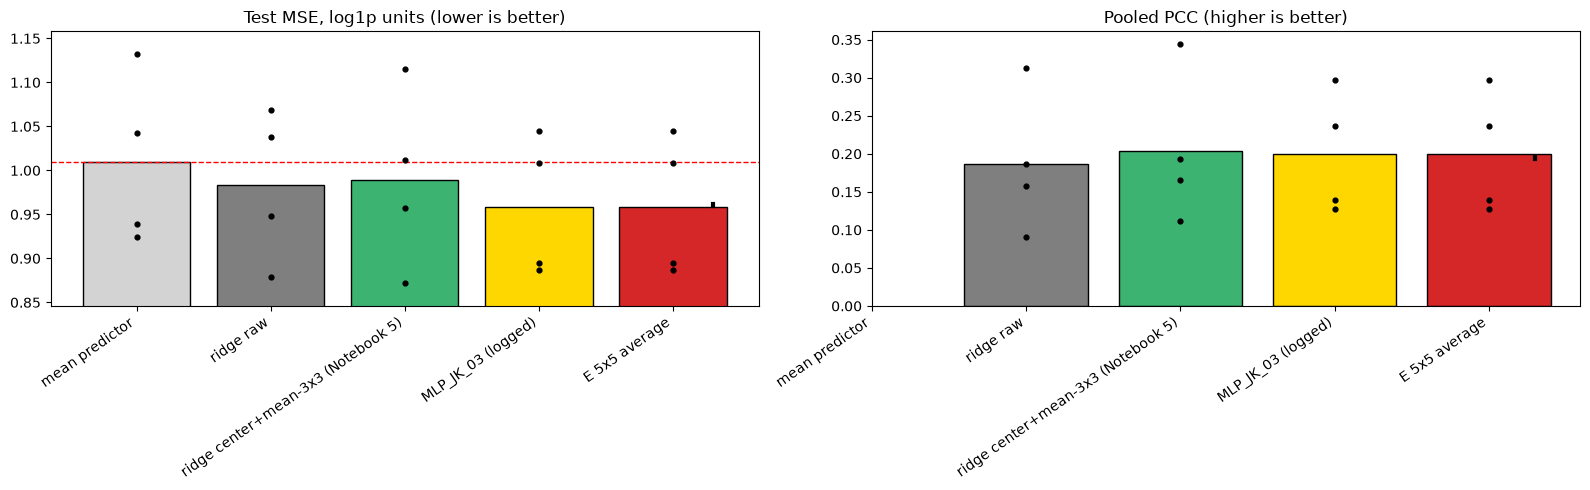

In [23]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    ridge_reference_name: "mediumseagreen",
    REFERENCE_NAME: "gold",
    SETUP_NAMES["A"]: "tab:blue",
    SETUP_NAMES["B"]: "tab:purple",
    SETUP_NAMES["C"]: "orchid",
    SETUP_NAMES["D"]: "tab:orange",
    SETUP_NAMES["E"]: "tab:red",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(model_order))
for ax, column, spread_column, title in [(axes[0], "MSE", "MSE", "Test MSE, log1p units (lower is better)"),
                                         (axes[1], "PCC", "PCC", "Pooled PCC (higher is better)")]:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        spread = seed_spread[seed_spread["model"] == model_name]
        if len(spread) > 0:
            ax.plot([i + 0.3, i + 0.3], [spread[f"{spread_column}_min"].iloc[0], spread[f"{spread_column}_max"].iloc[0]],
                    color="black", linewidth=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.set_title(title)
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores["MSE"].min()
high = fold_scores["MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

**Per fold.** Each line is one test fold. Lines going up or down together between two setups mean the difference is consistent across patients.

**Workflow overview:** draws saved comparison figures.

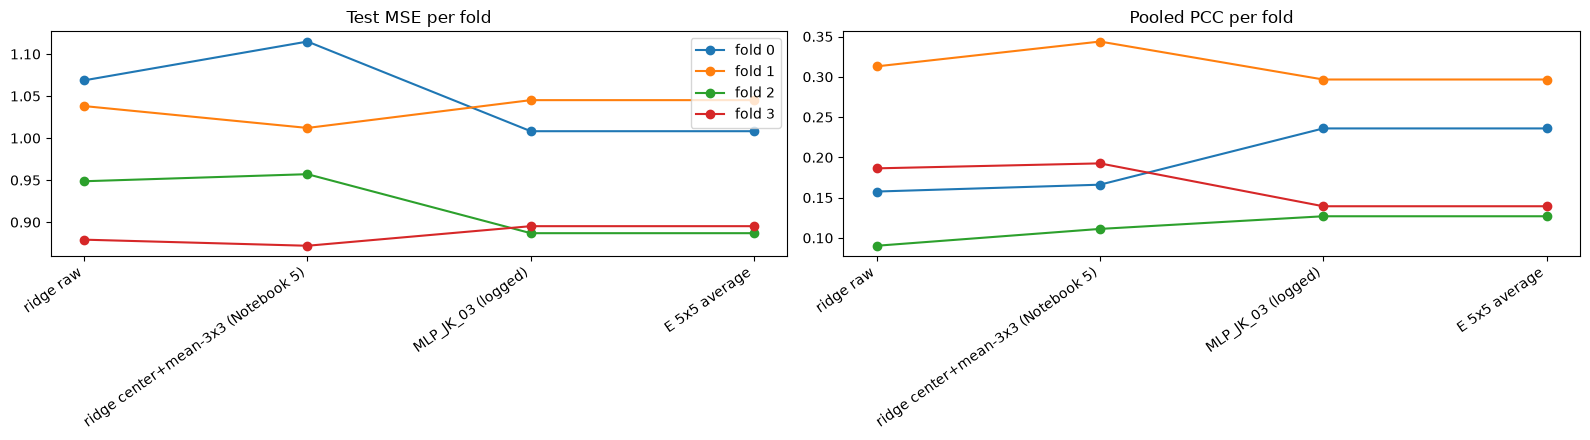

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
models_to_plot = [m for m in model_order if m != "mean predictor"]
for ax, column, title in [(axes[0], "MSE", "Test MSE per fold"), (axes[1], "PCC", "Pooled PCC per fold")]:
    table = fold_scores.pivot(index="model", columns="fold", values=column)
    for fold in range(N_FOLDS):
        ax.plot(range(len(models_to_plot)), [table.loc[m, fold] for m in models_to_plot], marker="o", label=f"fold {fold}")
    ax.set_xticks(range(len(models_to_plot)))
    ax.set_xticklabels(models_to_plot, rotation=35, ha="right")
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
save_figure("2_per_fold.png")
plt.show()

## Step 14. Save results and add them to the log

`all_results.csv` gets one row per model run in this notebook: the mean predictor, ridge raw, and the 5 setups. (The reference rows read from other notebooks aren't added again.) If this notebook is run again, its old rows are replaced instead of duplicated.

**Workflow overview:** writes metrics and experiment settings.

In [25]:
summary.to_csv(OUT_DIR / "summary.csv", index=False)
seed_spread.to_csv(OUT_DIR / "seed_spread.csv", index=False)
fold_scores.to_csv(OUT_DIR / "fold_scores.csv", index=False)
pooled.to_csv(OUT_DIR / "pooled_gene_scores.csv", index=False)
within.to_csv(OUT_DIR / "within_patient_gene_scores.csv", index=False)
val_scores.to_csv(OUT_DIR / "validation_scores.csv", index=False)
chosen_settings.to_csv(OUT_DIR / "chosen_settings.csv", index=False)
if NOTEBOOK_NAME == "MLP_JK_03":
    best_check.to_csv(OUT_DIR / "best_check.csv", index=False)
loss_history.to_csv(OUT_DIR / "loss_history.csv", index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "setups": SETUPS,
    "setup_names": SETUP_NAMES,
    "input_sizes": INPUT_SIZES,
    "new_best_setup": new_best_setup if NOTEBOOK_NAME == "MLP_JK_03" else None,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "slot_offsets": SLOT_OFFSETS,
    "n_pcs": N_PCS,
    "n_neighbor_pcs": N_NEIGHBOR_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with Path(OUT_DIR / "settings.json").open("w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] in [ridge_reference_name, REFERENCE_NAME]:
            continue
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row["val_PCC"],
            "val_NRMSE": row["val_NRMSE"],
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if RESULTS_LOG.exists():
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted([item.name for item in OUT_DIR.iterdir()]):
    print("  ", name)


Saved to /Users/jk/JHU/BDD/MLP_JK/results/MLP_JK_Best
   1_mse_and_pcc.png
   2_per_fold.png
   chosen_settings.csv
   fold_scores.csv
   loss_history.csv
   pooled_gene_scores.csv
   seed_spread.csv
   settings.json
   summary.csv
   validation_scores.csv
   within_patient_gene_scores.csv


## Summary in plain words

**Reproduction:** this run gives exactly the same numbers as setup E in MLP_JK_03 (pooled PCC 0.1997, NRMSE 1.0702, the same `k` = 0.4 and epochs in every fold), and ridge raw reproduces Notebook 5 (0.187).

**Why this is the best:** it has the highest validation PCC of any MLP so far (0.226, vs. 0.211 for the previous best from MLP_JK_02), and its validation NRMSE (1.084) is below the mean predictor's (1.113). The previous best notebook and its results are kept in `archive/MLP_JK_Best_from_MLP_JK_02/`.

| Score | What it means | Good vs. bad | Mean predictor | Best ridge (NB 5) | Previous best (02) | **Current best (E)** |
|---|---|---|---|---|---|---|
| **Test MSE** | Average squared error in log1p expression | Lower is better | 1.009 | 0.989 | 0.966 | **0.959** |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots | 0 = none, 1 = perfect | — | **0.203** | 0.198 | 0.200 |
| **Within-patient PCC** | The same, inside one patient at a time | Higher is better | — | 0.161 | 0.161 | **0.169** |
| **NRMSE** | Error divided by the gene's spread | Lower is better; must be below the mean predictor | 1.100 | 1.093 | 1.075 | **1.070** |
| **Validation PCC** | Pooled PCC on held-out training patients; used to choose | Higher is better | — | — | 0.211 | **0.226** |

**In short:** the center spot plus the 5×5 neighborhood average, each compressed with PCA 256, fed to a small MLP and shrunk toward the training mean (`k` = 0.4). It has the lowest error and the best within-patient ranking of any model so far. Its pooled PCC is about the same as the best ridge.

**To replace this model:** a new experiment must have a higher validation PCC (averaged over 4 validation groups of training patients) with validation NRMSE no worse than the mean predictor's.